<a href="https://colab.research.google.com/github/Nourhan908/CNN-Fashion-_store/blob/main/nlp_ass1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1.load

In [22]:

import pandas as pd

# Load the dataset from the same folder as this notebook
df = pd.read_csv("synthetic_text_data.csv")

# Display the first 5 rows
df.head()


,text,label
0,Artificial intelligence is advancing in health...,Technology
1,Football fans are excited about the upcoming W...,Sports
2,New policies regarding climate change have spa...,Politics
3,The latest blockbuster movie has shattered box...,Entertainment
4,Quantum computing promises to revolutionize in...,Technology


In [23]:

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column names and data types
print("\nDataset information:")
df.info()

# Count missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Display the number of examples in each category
print("\nClass distribution:")
print(df["label"].value_counts())

# Display a few random examples
print("\nRandom examples:")
df.sample(min(5, len(df)), random_state=42)


Dataset shape: (85, 2)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85 entries, 0 to 84
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    85 non-null     object
 1   label   85 non-null     object
dtypes: object(2)
memory usage: 1.5+ KB

Missing values:
text     0
label    0
dtype: int64

Class distribution:
label
Technology       30
Politics         21
Entertainment    19
Sports           15
Name: count, dtype: int64

Random examples:


,text,label
78,National debates on the legalization of mariju...,Politics
0,Artificial intelligence is advancing in health...,Technology
68,"Self-driving cars are becoming a reality, with...",Technology
22,The debate on free speech continues to be a ho...,Politics
12,Video game developers are excited about the re...,Entertainment


In [24]:

# Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check for duplicate sentences
print("Duplicate sentences:", df["text"].duplicated().sum())

# Check for empty or whitespace-only sentences
print("Empty sentences:", df["text"].str.strip().eq("").sum())

# Check for missing labels
print("Missing labels:", df["label"].isna().sum())

# Confirm the column names
print("Columns:", df.columns.tolist())


Duplicate rows: 0
Duplicate sentences: 0
Empty sentences: 0
Missing labels: 0
Columns: ['text', 'label']


#2.preprocess

In [25]:

import re

def preprocess_text(text):
    # Convert text to lowercase
    text = text.lower()

    # Keep letters and numbers; replace punctuation with spaces
    text = re.sub(r"[^\w\s]", " ", text)

    # Split the sentence into individual words
    tokens = text.split()

    return tokens


# Apply preprocessing to every sentence
df["tokens"] = df["text"].apply(preprocess_text)

# Compare original sentences with their processed tokens
df[["text", "tokens", "label"]].head(10)


,text,tokens,label
0,Artificial intelligence is advancing in health...,"[artificial, intelligence, is, advancing, in, ...",Technology
1,Football fans are excited about the upcoming W...,"[football, fans, are, excited, about, the, upc...",Sports
2,New policies regarding climate change have spa...,"[new, policies, regarding, climate, change, ha...",Politics
3,The latest blockbuster movie has shattered box...,"[the, latest, blockbuster, movie, has, shatter...",Entertainment
4,Quantum computing promises to revolutionize in...,"[quantum, computing, promises, to, revolutioni...",Technology
5,Political debates are becoming more heated as ...,"[political, debates, are, becoming, more, heat...",Politics
6,Tech companies are investing heavily in artifi...,"[tech, companies, are, investing, heavily, in,...",Technology
7,"The summer Olympics are fast approaching, and ...","[the, summer, olympics, are, fast, approaching...",Sports
8,Music festivals are back this year with global...,"[music, festivals, are, back, this, year, with...",Entertainment
9,The rise of self-driving cars is changing the ...,"[the, rise, of, self, driving, cars, is, chang...",Technology


#3.split

In [26]:

from sklearn.model_selection import train_test_split

# Split the data while preserving class proportions
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["label"]
)

# Check the sizes of the two sets
print("Training set size:", len(train_df))
print("Testing set size:", len(test_df))

# Compare class distributions
print("\nTraining class distribution:")
print(train_df["label"].value_counts())

print("\nTesting class distribution:")
print(test_df["label"].value_counts())


Training set size: 68
Testing set size: 17

Training class distribution:
label
Technology       24
Politics         17
Entertainment    15
Sports           12
Name: count, dtype: int64

Testing class distribution:
label
Technology       6
Politics         4
Entertainment    4
Sports           3
Name: count, dtype: int64


#4.build the vocab

In [27]:

# Build the vocabulary using training tokens only
vocabulary = sorted({
    word
    for tokens in train_df["tokens"]
    for word in tokens
})

# Assign each word a unique numerical index
word_to_index = {
    word: index
    for index, word in enumerate(vocabulary)
}

# Inspect the vocabulary
print("Vocabulary size:", len(vocabulary))
print("\nFirst 30 words:")
print(vocabulary[:30])

print("\nFirst 10 word-to-index mappings:")
print(list(word_to_index.items())[:10])


Vocabulary size: 391

First 30 words:
['a', 'about', 'across', 'action', 'activities', 'actors', 'adapt', 'address', 'advancing', 'advertisements', 'after', 'ai', 'airwaves', 'an', 'and', 'announced', 'applications', 'apps', 'are', 'areas', 'around', 'artificial', 'as', 'assist', 'assistants', 'attendance', 'attracting', 'audiences', 'augmented', 'automation']

First 10 word-to-index mappings:
[('a', 0), ('about', 1), ('across', 2), ('action', 3), ('activities', 4), ('actors', 5), ('adapt', 6), ('address', 7), ('advancing', 8), ('advertisements', 9)]


#5.Bag of words

In [28]:

import numpy as np

def text_to_bow(tokens, word_to_index):
    # Create a vector of zeros, one position per vocabulary word
    vector = np.zeros(len(word_to_index), dtype=int)

    # Count each token if it exists in the training vocabulary
    for word in tokens:
        if word in word_to_index:
            vector[word_to_index[word]] += 1

    return vector


# Convert training and testing sentences into BoW matrices
X_train = np.array([
    text_to_bow(tokens, word_to_index)
    for tokens in train_df["tokens"]
])

X_test = np.array([
    text_to_bow(tokens, word_to_index)
    for tokens in test_df["tokens"]
])

# Extract the corresponding labels
y_train = train_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

# Check the resulting shapes
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


X_train shape: (68, 391)
X_test shape: (17, 391)
y_train shape: (68,)
y_test shape: (17,)


#6.data visualization

In [29]:

import matplotlib.pyplot as plt
from collections import Counter


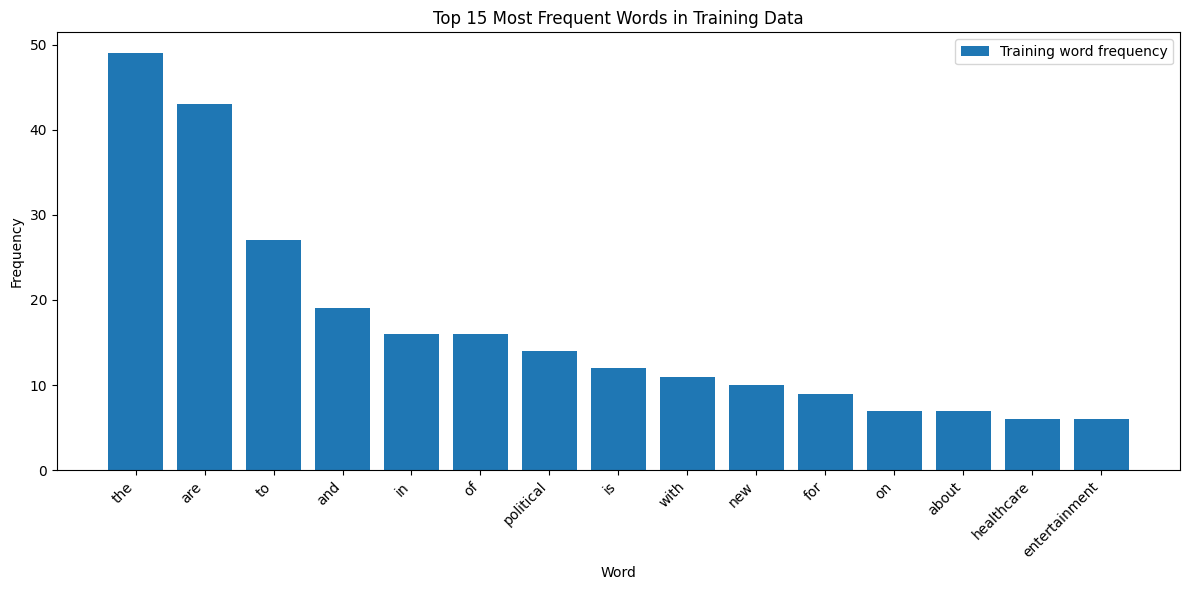

In [30]:

# Count all tokens in the training set
all_train_tokens = [
    word
    for tokens in train_df["tokens"]
    for word in tokens
]

word_counts = Counter(all_train_tokens)

# Select the 15 most frequent words
top_words = word_counts.most_common(15)

words = [word for word, count in top_words]
frequencies = [count for word, count in top_words]

# Plot the results
plt.figure(figsize=(12, 6))
plt.bar(words, frequencies, label="Training word frequency")

plt.title("Top 15 Most Frequent Words in Training Data")
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()


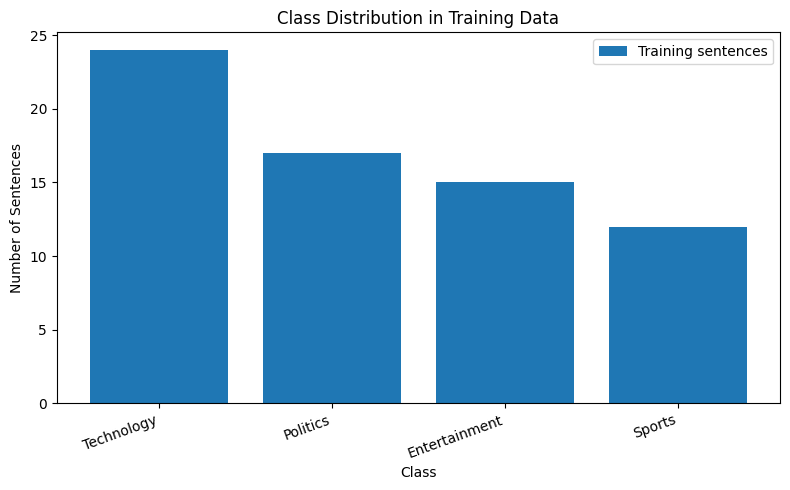

In [31]:

# Count examples in each training class
class_counts = train_df["label"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(class_counts.index, class_counts.values, label="Training sentences")

plt.title("Class Distribution in Training Data")
plt.xlabel("Class")
plt.ylabel("Number of Sentences")
plt.xticks(rotation=20, ha="right")
plt.legend()
plt.tight_layout()
plt.show()


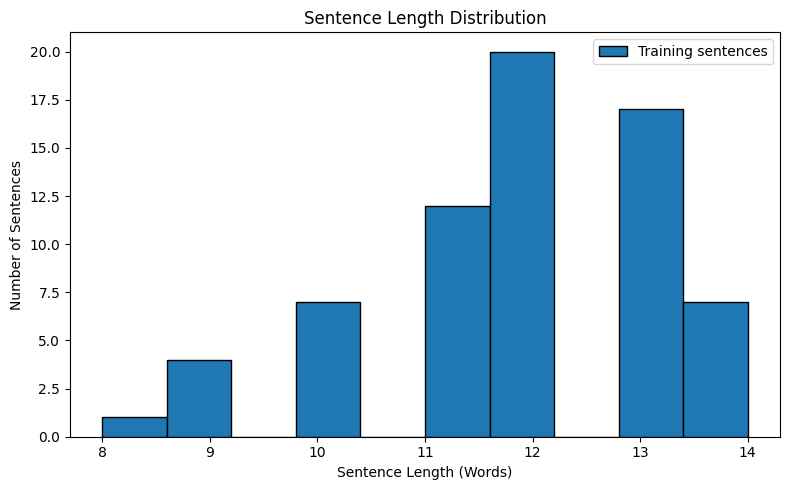

In [32]:

# Calculate the number of tokens in each training sentence
train_df["sentence_length"] = train_df["tokens"].apply(len)

plt.figure(figsize=(8, 5))
plt.hist(
    train_df["sentence_length"],
    bins=10,
    edgecolor="black",
    label="Training sentences"
)

plt.title("Sentence Length Distribution")
plt.xlabel("Sentence Length (Words)")
plt.ylabel("Number of Sentences")
plt.legend()
plt.tight_layout()
plt.show()


In [33]:

%pip install wordcloud


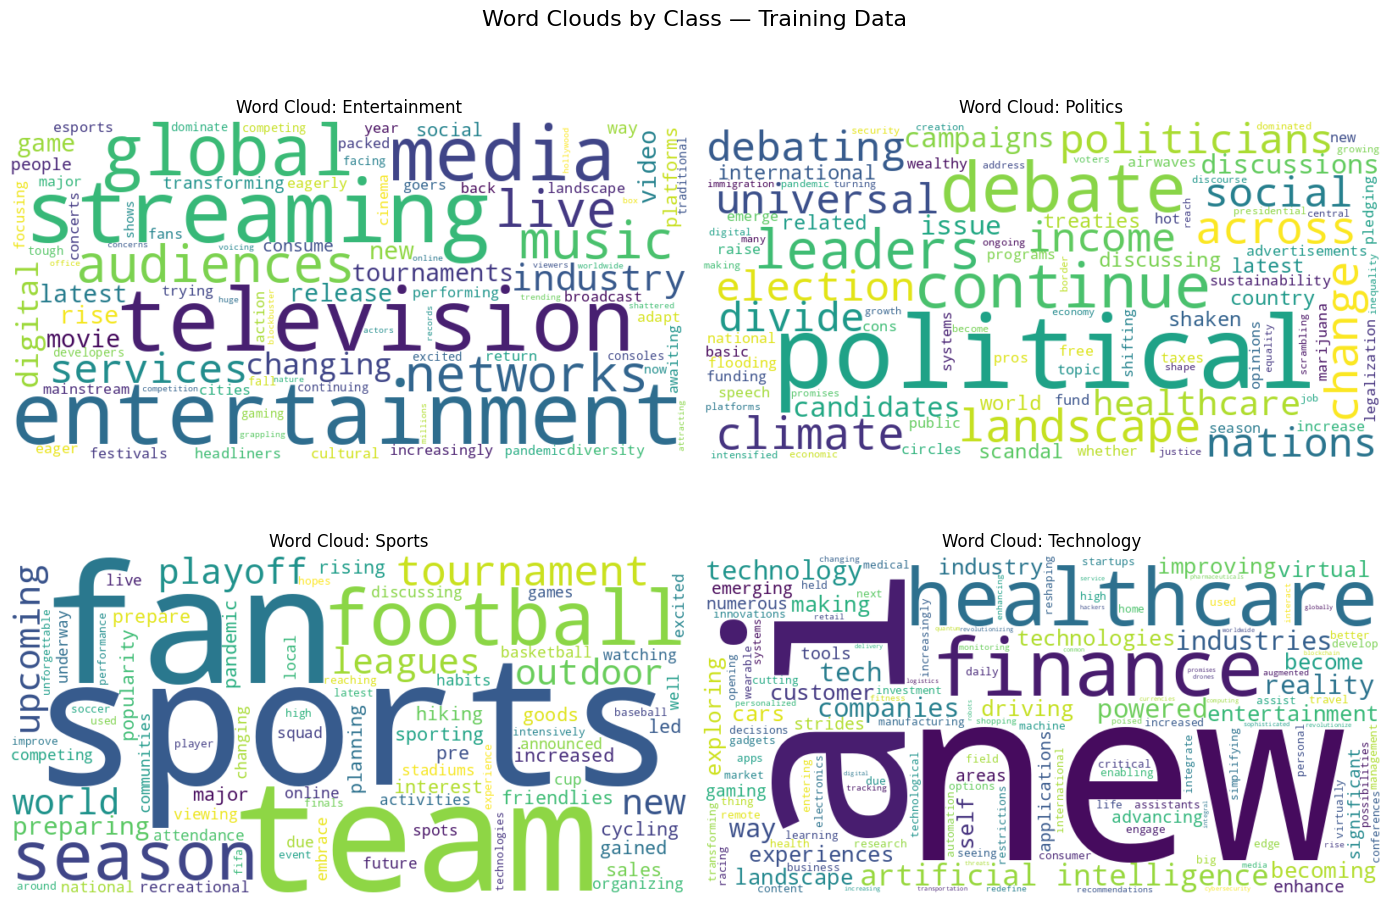

In [34]:

from wordcloud import WordCloud

# Generate one word cloud for each training class
classes = sorted(train_df["label"].unique())

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, category in zip(axes, classes):
    # Combine the tokens from sentences in this class
    class_tokens = [
        word
        for tokens in train_df.loc[
            train_df["label"] == category, "tokens"
        ]
        for word in tokens
    ]

    class_text = " ".join(class_tokens)

    # Generate the word cloud
    cloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(class_text)

    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(f"Word Cloud: {category}")
    ax.axis("off")

fig.suptitle("Word Clouds by Class — Training Data", fontsize=16)
plt.tight_layout()
plt.show()


#7.naive bayes from scratch

In [35]:

from collections import Counter, defaultdict
import numpy as np

# Get the unique classes from the training labels
classes = sorted(set(y_train))

# Calculate the number of training examples in each class
class_document_counts = Counter(y_train)

# Calculate the prior probability for each class
class_priors = {
    category: class_document_counts[category] / len(y_train)
    for category in classes
}

# Count how often each vocabulary word appears in each class
class_word_counts = {}
class_total_words = {}

for category in classes:
    # Find the training rows belonging to this class
    category_rows = X_train[y_train == category]

    # Sum word counts column by column
    word_counts = category_rows.sum(axis=0)

    class_word_counts[category] = word_counts
    class_total_words[category] = word_counts.sum()

# Display the results
print("Class priors:")
for category in classes:
    print(f"{category}: {class_priors[category]:.4f}")

print("\nTotal token counts per class:")
for category in classes:
    print(f"{category}: {class_total_words[category]}")


Class priors:
Entertainment: 0.2206
Politics: 0.2500
Sports: 0.1765
Technology: 0.3529

Total token counts per class:
Entertainment: 182
Politics: 200
Sports: 152
Technology: 271


In [36]:

# Laplace smoothing parameter
alpha = 1

# Vocabulary size
vocab_size = len(vocabulary)

# Store the log probability of every word in every class
class_word_log_probs = {}

for category in classes:
    word_counts = class_word_counts[category]
    total_words = class_total_words[category]

    # Apply Laplace smoothing to every vocabulary word
    probabilities = (
        word_counts + alpha
    ) / (
        total_words + alpha * vocab_size
    )

    # Log probabilities make multiplication numerically stable
    class_word_log_probs[category] = np.log(probabilities)

print("Vocabulary size:", vocab_size)
print("Smoothing alpha:", alpha)

print("\nExample word probabilities:")
for word in ["artificial", "football", "political"]:
    if word in word_to_index:
        index = word_to_index[word]
        print(f"\nWord: {word}")

        for category in classes:
            probability = np.exp(class_word_log_probs[category][index])
            print(f"  {category}: {probability:.6f}")


Vocabulary size: 391
Smoothing alpha: 1

Example word probabilities:

Word: artificial
  Entertainment: 0.001745
  Politics: 0.001692
  Sports: 0.001842
  Technology: 0.007553

Word: football
  Entertainment: 0.001745
  Politics: 0.001692
  Sports: 0.007366
  Technology: 0.001511

Word: political
  Entertainment: 0.001745
  Politics: 0.025381
  Sports: 0.001842
  Technology: 0.001511


In [37]:

def predict_one(tokens):
    # Convert the sentence into a BoW vector
    bow = text_to_bow(tokens, word_to_index)

    class_scores = {}

    for category in classes:
        # Start with the log prior probability
        score = np.log(class_priors[category])

        # Add the log likelihood of each word, weighted by its count
        score += np.dot(bow, class_word_log_probs[category])

        class_scores[category] = score

    # Return the class with the highest score
    predicted_class = max(class_scores, key=class_scores.get)

    return predicted_class


# Test the function on three training sentences
for i in range(3):
    sentence_tokens = train_df.iloc[i]["tokens"]
    actual_label = train_df.iloc[i]["label"]
    predicted_label = predict_one(sentence_tokens)

    print("Sentence:", train_df.iloc[i]["text"])
    print("Actual:", actual_label)
    print("Predicted:", predicted_label)
    print("-" * 50)


Sentence: Football teams are planning pre-season friendlies to prepare for the new season.
Actual: Sports
Predicted: Sports
--------------------------------------------------
Sentence: Artificial intelligence is advancing in healthcare with numerous applications emerging.
Actual: Technology
Predicted: Technology
--------------------------------------------------
Sentence: Social media platforms are transforming the way people consume news and entertainment.
Actual: Entertainment
Predicted: Entertainment
--------------------------------------------------


In [38]:

# Predict labels for the training and test sets
y_train_pred_manual = np.array([
    predict_one(tokens) for tokens in train_df["tokens"]
])

y_test_pred_manual = np.array([
    predict_one(tokens) for tokens in test_df["tokens"]
])

# Calculate accuracy
train_accuracy_manual = np.mean(y_train_pred_manual == y_train)
test_accuracy_manual = np.mean(y_test_pred_manual == y_test)

print(f"Manual Naive Bayes Training Accuracy: {train_accuracy_manual:.2%}")
print(f"Manual Naive Bayes Test Accuracy: {test_accuracy_manual:.2%}")
print(f"Correct test predictions: {(y_test_pred_manual == y_test).sum()} out of {len(y_test)}")


Manual Naive Bayes Training Accuracy: 100.00%
Manual Naive Bayes Test Accuracy: 82.35%
Correct test predictions: 14 out of 17


#8.naive bayes with scikit learn

In [39]:

from sklearn.naive_bayes import MultinomialNB
import numpy as np

# Create and train the Scikit-learn model
sklearn_nb = MultinomialNB(alpha=1.0)
sklearn_nb.fit(X_train, y_train)

# Predict labels for both datasets
y_train_pred_sklearn = sklearn_nb.predict(X_train)
y_test_pred_sklearn = sklearn_nb.predict(X_test)

# Calculate accuracy
train_accuracy_sklearn = np.mean(y_train_pred_sklearn == y_train)
test_accuracy_sklearn = np.mean(y_test_pred_sklearn == y_test)

print(f"Scikit-learn Training Accuracy: {train_accuracy_sklearn:.2%}")
print(f"Scikit-learn Test Accuracy: {test_accuracy_sklearn:.2%}")


Scikit-learn Training Accuracy: 100.00%
Scikit-learn Test Accuracy: 82.35%


#9.compare models prediction

In [40]:

# Compare predictions on the test set
same_predictions = y_test_pred_manual == y_test_pred_sklearn
different_predictions = ~same_predictions

print("Total test sentences:", len(y_test))
print("Matching predictions:", same_predictions.sum())
print("Different predictions:", different_predictions.sum())

# Display any disagreements
print("\nSentences where the models disagree:")

for i in np.where(different_predictions)[0]:
    print("\nSentence:", test_df.iloc[i]["text"])
    print("Actual label:", y_test[i])
    print("Manual prediction:", y_test_pred_manual[i])
    print("Scikit-learn prediction:", y_test_pred_sklearn[i])


Total test sentences: 17
Matching predictions: 17
Different predictions: 0

Sentences where the models disagree:


#10.confusion matrix

MANUAL NAIVE BAYES — TEST CLASSIFICATION REPORT
               precision    recall  f1-score   support

Entertainment       1.00      0.75      0.86         4
     Politics       0.80      1.00      0.89         4
       Sports       1.00      0.67      0.80         3
   Technology       0.71      0.83      0.77         6

     accuracy                           0.82        17
    macro avg       0.88      0.81      0.83        17
 weighted avg       0.85      0.82      0.82        17


SCIKIT-LEARN NAIVE BAYES — TEST CLASSIFICATION REPORT
               precision    recall  f1-score   support

Entertainment       1.00      0.75      0.86         4
     Politics       0.80      1.00      0.89         4
       Sports       1.00      0.67      0.80         3
   Technology       0.71      0.83      0.77         6

     accuracy                           0.82        17
    macro avg       0.88      0.81      0.83        17
 weighted avg       0.85      0.82      0.82        17



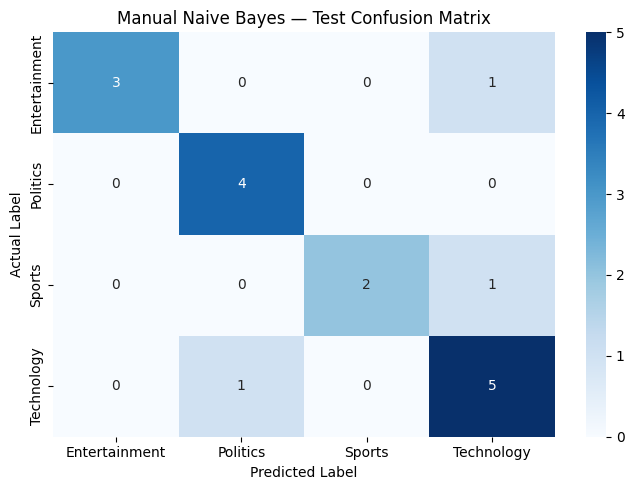

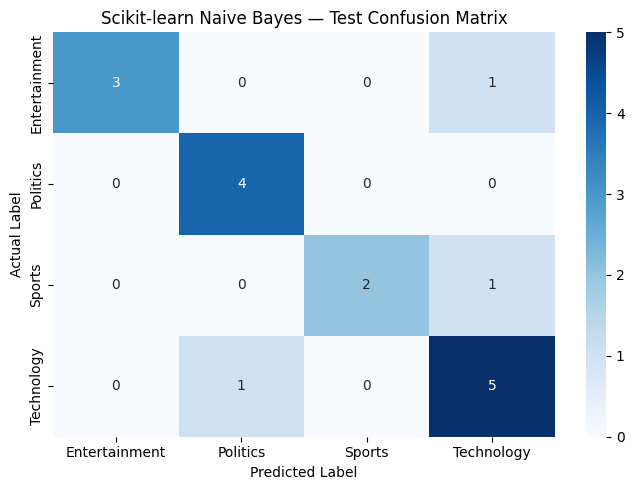

In [41]:

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Use a consistent class order
class_names = ["Entertainment", "Politics", "Sports", "Technology"]

# Classification reports on the test set
print("MANUAL NAIVE BAYES — TEST CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_test_pred_manual,
    labels=class_names,
    zero_division=0
))

print("\nSCIKIT-LEARN NAIVE BAYES — TEST CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_test_pred_sklearn,
    labels=class_names,
    zero_division=0
))

# Confusion matrix: Manual model
cm_manual = confusion_matrix(
    y_test, y_test_pred_manual, labels=class_names
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_manual, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names
)
plt.title("Manual Naive Bayes — Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

# Confusion matrix: Scikit-learn model
cm_sklearn = confusion_matrix(
    y_test, y_test_pred_sklearn, labels=class_names
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_sklearn, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names
)
plt.title("Scikit-learn Naive Bayes — Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()
